<a href="https://colab.research.google.com/github/zuvelatamara/PPPO-2025/blob/main/PPPO_V4_PyTorch_TensorFlow_Primer_NN_MetrikeV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PyTorch biblioteka
 PyTorch je open-source biblioteka za mašinsko učenje u Python-u koju je razvila Facebook-ova laboratorija za veštačku inteligenciju (FAIR).
 Široko se koristi za izradu modela dubokog učenja i istraživanja u različitim oblastima, poput **računarskog vida, obrade prirodnog jezika i ojačanog učenja (reinforcement learning)**.
Jedna od ključnih karakteristika PyTorch-a je **dinamički računarski graf**, koji omogućava fleksibilniju i intuitivniju izradu modela u poređenju sa statičkim grafovima.
PyTorch se takođe besprekorno integriše sa drugim popularnim bibliotekama kao što je **NumPy**, što olakšava rad sa tenzorima i višedimenzionalnim nizovima.

Zašto koristiti PyTorch?

* **Podržava računanje nad tenzorima:**
Tenzor je struktura podataka slična nizu (array-u), odnosno mreži. To je n-dimenzionalni niz koji sadrži podatke, a nad njim se mogu vršiti razne numeričke operacije korišćenjem dostupnih API-ja.

* **Omogućava dinamičko formiranje računskih grafova:**
Ova funkcionalnost omogućava da se računski graf definiše dinamički tokom izvršavanja programa, što pruža veću fleksibilnost u odnosu na statički pristup gde je struktura grafa unapred definisana i fiksna.

* **Nudi automatsku diferencijaciju:**
Paket Autograd automatski izračunava gradijente koji su neophodni za treniranje modela pomoću optimizacionih algoritama. Na taj način se mogu vršiti operacije nad tenzorima bez ručnog računanja gradijenata.

* **Ima punu podršku za Python:**
PyTorch ima nativnu podršku za programski jezik Python, što omogućava jednostavnu integraciju sa postojećim Python okruženjima i bibliotekama.
Zbog toga ga zajednice za mašinsko učenje i nauku o podacima široko koriste.

* **Podržava produkciono okruženje:**
PyTorch poseduje TorchScript, visoko-performansno okruženje za serijalizaciju i izvršavanje PyTorch modela.
Modeli se mogu kompajlirati u prenosivi međureprezentacioni (IR) format, što omogućava njihovo pokretanje na različitim platformama i uređajima, bez potrebe za izvornim Python kodom.

## Plan vežbe

1. **Tenzori u PyTorch-u**: kreiranje, operacije, indeksiranje i automatsko računanje gradijenata.
2. **Dataset i DataLoader**: kako se slike učitavaju u mini-batch-evima.
3. **TensorFlow / Keras**: treniranje neuronske mreže na tabelarnim podacima (dijabetes).
4. **PyTorch**: treniranje neuronske mreže na Iris skupu.
5. **Metrike**: matrica konfuzije, preciznost, odziv, F1, ROC kriva i AUC, i IoU za detekciju objekata.

In [1]:
# U Colab-u su torch i torchvision već instalirani; ova linija je potrebna samo na sopstvenom računaru
!pip install -q torch torchvision

### Priprema slika

Ćelija ispod sama pravi sve slike koje su potrebne u svesci, pa **ništa ne treba otpremati**. Koristimo test slike koje dolaze uz biblioteku scikit-image: mačku, šolju kafe i raketu. Od svake pravimo više varijanti, pa dobijamo mali skup podataka sa tri klase u folderima `data/macke`, `data/kafa` i `data/rakete`.

In [2]:
# PRIPREMA SLIKA: nije potrebno ništa otpremati.
# Slike pravimo od test slika koje dolaze uz biblioteku scikit-image (mačka, šolja kafe, raketa),
# a od svake pravimo više varijanti (ogledalo, rotacija, isečak, svetlina) da bismo imali mali skup podataka.
import os
from PIL import Image, ImageOps, ImageEnhance
from skimage import data

osnovne = {'macke': data.chelsea(), 'kafa': data.coffee(), 'rakete': data.rocket()}

def varijante(img):
    w, h = img.size
    return [img, ImageOps.mirror(img), img.rotate(10), img.rotate(-10),
            img.crop((0, 0, int(w*0.8), int(h*0.8))), img.crop((int(w*0.2), int(h*0.2), w, h)),
            ImageEnhance.Brightness(img).enhance(0.7), ImageEnhance.Brightness(img).enhance(1.3)]

for klasa, niz in osnovne.items():
    os.makedirs(f'/content/data/{klasa}', exist_ok=True)
    for i, v in enumerate(varijante(Image.fromarray(niz))):
        v.save(f'/content/data/{klasa}/{klasa}_{i}.jpg')

# Pojedinačne slike za IoU primer i mini zadatke
Image.fromarray(data.chelsea()).save('/content/cat.jpg')
Image.fromarray(data.chelsea()).save('/content/animal1.jpg')
Image.fromarray(data.astronaut()).save('/content/animal2.jpg')

for d in sorted(os.listdir('/content/data')):
    print(f'data/{d}: {len(os.listdir(f"/content/data/{d}"))} slika')

data/kafa: 8 slika
data/macke: 8 slika
data/rakete: 8 slika


**Tensori u PyTorch biblioteci**

Tensor je višedimenzionalni niz koji je osnovna struktura podataka koja se koristi u PyTorch-u (i mnogim drugim okvirima za mašinsko učenje).

In [3]:
# Uvozimo PyTorch biblioteku (koristi se za rad sa tenzorima i neuronskim mrežama)
import torch

# Kreiramo jednodimenzionalni tenzor (vektor)
tensor_1d = torch.tensor([1, 2, 3])
print("1D Tensor (Vektor):")
print(tensor_1d)
print()

# Kreiramo dvodimenzionalni tenzor (matricu)
tensor_2d = torch.tensor([[1, 2], [3, 4]])
print("2D Tensor (Matrica):")
print(tensor_2d)
print()

# Kreiramo tenzor sa slučajnim vrednostima dimenzija 2x3
# Svaka vrednost je realan broj između 0 i 1
random_tensor = torch.rand(2, 3)
print("Nasumični Tensor (2x3):")
print(random_tensor)
print()

# Kreiramo tenzor popunjen nulama dimenzija 2x3
zeros_tensor = torch.zeros(2, 3)
print("Tensor Nula (2x3):")
print(zeros_tensor)
print()

# Kreiramo tenzor popunjen jedinicama dimenzija 2x3
ones_tensor = torch.ones(2, 3)
print("Tensor Jedinica (2x3):")
print(ones_tensor)


1D Tensor (Vektor):
tensor([1, 2, 3])

2D Tensor (Matrica):
tensor([[1, 2],
        [3, 4]])

Nasumični Tensor (2x3):
tensor([[0.3214, 0.3838, 0.2001],
        [0.5124, 0.5483, 0.0165]])

Tensor Nula (2x3):
tensor([[0., 0., 0.],
        [0., 0., 0.]])

Tensor Jedinica (2x3):
tensor([[1., 1., 1.],
        [1., 1., 1.]])


In [4]:
# Kreiranje tenzora iz liste
tensor1 = torch.tensor([1, 2, 3])
print("Tenzor iz liste:", tensor1)

# Kreiranje tenzora sa nulama dimenzija (2, 3)
tensor2 = torch.zeros(2, 3)
print("Tenzor nula:", tensor2)

# Kreiranje nasumičnog tenzora dimenzija (3, 2)
tensor3 = torch.rand(3, 2)
print("Nasumični tenzor:", tensor3)

# Operacije nad tenzorima

# Sabiranje: tensor1 je oblika (3,), a tensor2 (2, 3).
# PyTorch "proširi" tensor1 na oba reda (broadcasting), pa se on dodaje svakom redu tensor2.
result_add = tensor1 + tensor2
print("Rezultat sabiranja:", result_add)

# Množenje skalarom: svaki element se množi sa 5
result_mul = tensor2 * 5
print("Rezultat množenja skalarom:", result_mul)

# Množenje matrica: (2, 3) x (3, 2) = (2, 2)
result_matmul = torch.matmul(tensor2, tensor3)
print("Rezultat množenja matrica:", result_matmul, result_matmul.shape)

Tenzor iz liste: tensor([1, 2, 3])
Tenzor nula: tensor([[0., 0., 0.],
        [0., 0., 0.]])
Nasumični tenzor: tensor([[0.5766, 0.1181],
        [0.5050, 0.4756],
        [0.3186, 0.1448]])
Rezultat sabiranja: tensor([[1., 2., 3.],
        [1., 2., 3.]])
Rezultat množenja skalarom: tensor([[0., 0., 0.],
        [0., 0., 0.]])
Rezultat množenja matrica: tensor([[0., 0.],
        [0., 0.]]) torch.Size([2, 2])


**Tenzorske operacije u PyTorch-u**

PyTorch operacije su neophodne za efikasno manipulisanje podacima, posebno prilikom pripreme podataka za zadatke mašinskog učenja.

1. **Indeksiranje**: Indeksiranje vam omogućava da preuzmete određene elemente ili manje delove iz većeg tenzora.
2. **Isecanje**: Isecanje vam omogućava da izvadite deo tenzora određivanjem opsega redova ili kolona.
3. **Preoblikovanje**: Preoblikovanje menja oblik ili dimenzije tenzora bez promene njegovih stvarnih podataka. To znači da možete reorganizovati tenzor u drugu veličinu, a da pritom zadržite sve originalne vrednosti.


In [5]:
import torch

tensor = torch.tensor([[1, 2], [3, 4], [5, 6]])

element = tensor[1, 0]
print(f"Indexed Element (Row 1, Column 0): {element}")
slice_tensor = tensor[:2, :]
print(f"Sliced Tensor (First two rows): \n{slice_tensor}")

reshaped_tensor = tensor.view(2, 3)
print(f"Reshaped Tensor (2x3): \n{reshaped_tensor}")

Indexed Element (Row 1, Column 0): 3
Sliced Tensor (First two rows): 
tensor([[1, 2],
        [3, 4]])
Reshaped Tensor (2x3): 
tensor([[1, 2, 3],
        [4, 5, 6]])


In [6]:
# Definisanje tenzora sa requires_grad=True da bi se pratila istorija izračunavanja
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

# Računanje
z = x**2 + y**3
print("Output tensor z:", z)

# Dobijanje gradijenta
z.backward()
print("Gradient of x:", x.grad)
print("Gradient of y:", y.grad)

Output tensor z: tensor(31., grad_fn=<AddBackward0>)
Gradient of x: tensor(4.)
Gradient of y: tensor(27.)


**DataLoader i Dataset u PyTorch biblioteci**



Klase **DataLoader** i **Dataset** u PyTorch-u predstavljaju glavne komponente za učitavanje i iteraciju kroz skupove podataka.

Klasa Dataset služi kao interfejs za prilagođene (custom) skupove podataka (npr. učitava slike iz foldera ili podatke iz CSV fajla).
Služi za učitavanje i pripremu podataka.


Da bi se kreirao prilagođeni dataset za izgradnju modela u PyTorch-u, potrebno je implementirati metode:
*  __len__ - pročita koliko podataka ukupno ima i
*  __getitem__ - pročita jedan podatak po indeksu.

Klasa DataLoader iterira odnosno, omogućava lakše prolaziti kroz dataset u mini-batch-evima. Koristi se u treniranju modela da se ne učitavaju svi podaci odjednom u memoriju.
Takođe može nasumično mešati podatke (**shuffle**) i koristiti višestruke procesore (**num_workers**) za brže učitavanje.

Nakon toga ih prenosi na odgovarajući uređaj (CPU ili GPU), kako bi model mogao da ih obradi.


**PRIMER 1**

In [7]:
!ls data
!rm -rf data/.ipynb_checkpoints


kafa  macke  rakete


Shape batch-a: torch.Size([5, 3, 256, 256])
Labels: tensor([0, 1, 2, 2, 0])


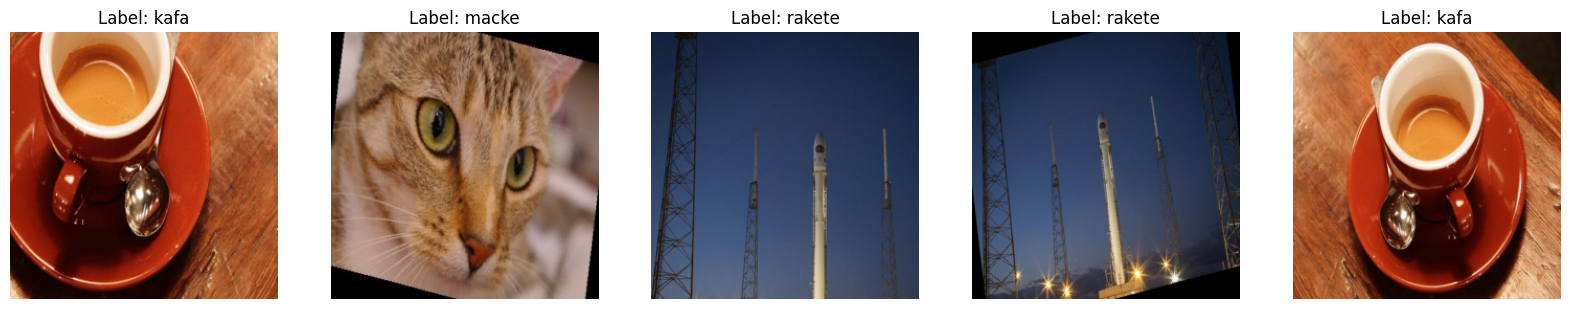

In [8]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Definišemo transformacije (obradu slike pre učenja)
transform = transforms.Compose([
    transforms.Resize((256, 256)),   # promena veličine slike
    transforms.ToTensor(),           # pretvaranje slike u PyTorch tensor
])

# 2. Kreiramo Dataset iz foldera sa slikama
# Struktura foldera mora biti (ime foldera = ime klase):
# data/
# ├── kafa/
# │   ├── kafa_0.jpg
# │   └── ...
# ├── macke/
# │   ├── macke_0.jpg
# │   └── ...
# └── rakete/
#     ├── rakete_0.jpg
#     └── ...

dataset = datasets.ImageFolder(root='/content/data', transform=transform)

# 3. Kreiramo DataLoader za prolazak kroz slike
dataloader = DataLoader(dataset, batch_size=5, shuffle=True)

# 4. Pogledajmo jedan batch slika
images, labels = next(iter(dataloader))  # uzimamo prvi batch

print("Shape batch-a:", images.shape)  # (batch_size, kanali, visina, širina) = (5, 3, 256, 256)
print("Labels:", labels)

#  5. Prikaz slika
fig, axes = plt.subplots(1, len(images), figsize=(20, 10))
for i in range(len(images)):
    img = images[i].permute(1, 2, 0)
    axes[i].imshow(img)
    axes[i].set_title(f"Label: {dataset.classes[labels[i]]}")
    axes[i].axis('off')
plt.show()


**PRIMER 2**

Batch 1: Inputs shape = torch.Size([4, 3, 128, 128]), Labels = torch.Size([4])
Batch 2: Inputs shape = torch.Size([4, 3, 128, 128]), Labels = torch.Size([4])


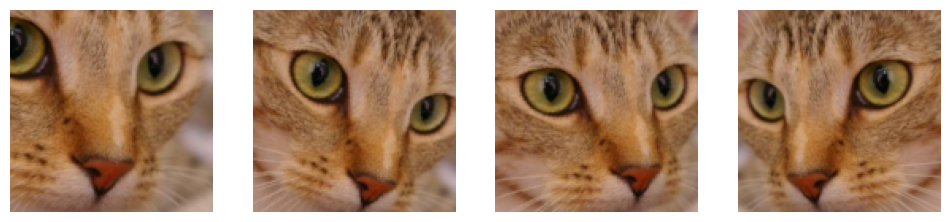

In [9]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Custom Dataset klasa koja učitava slike iz foldera
class CustomImageDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        # lista svih fajlova u direktorijumu
        self.image_files = [f for f in os.listdir(image_dir)
                            if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        # putanja do slike
        img_path = os.path.join(self.image_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # dummy labela (ako nema klasifikacije)
        label = 0
        return image, label


# Transformacije nad slikama (resize + tensor)
transform = transforms.Compose([
    transforms.Resize(150),
    transforms.CenterCrop(128),
    transforms.ToTensor()
])

#  Folder sa slikama (ovde slike mačaka koje smo napravili na početku)
image_dir = "data/macke"

# Kreiraj dataset
dataset = CustomImageDataset(image_dir=image_dir, transform=transform)

# Kreiraj DataLoader
data_loader = DataLoader(dataset, batch_size=4, shuffle=True)

# Iteracija kroz DataLoader
for batch_idx, (inputs, labels) in enumerate(data_loader):
    print(f"Batch {batch_idx+1}: Inputs shape = {inputs.shape}, Labels = {labels.shape}")
    if batch_idx == 1:  # prikažemo samo prva 2 batcha
        break

# Prikaz nekoliko slika
import matplotlib.pyplot as plt

images, labels = next(iter(data_loader))

fig, axes = plt.subplots(1, len(images), figsize=(12, 3))
for i, img in enumerate(images):
    img = img.permute(1, 2, 0)  # (C, H, W) → (H, W, C)
    axes[i].imshow(img)
    axes[i].axis('off')
plt.show()


**TensorFlow**


TensorFlow je okvir za mašinsko učenje otvorenog koda baziran na Google Brain-u, koji je veoma adaptivan i skalabilan. Proširuje podršku na različite platforme, od mobilnih uređaja do distribuiranih računarskih klastera.

Ključne karakteristike TensorFlow-a su:
* **TensorFlow izračunavanje:** TensorFlow je prvobitno koristio statički graf izračunavanja, gde se prvo definiše ceo graf izračunavanja, a zatim se izvršava. Ovo je urađeno korišćenjem TensorFlow 1.x i tf.Graph API-ja. Sa TensorFlow 2.x, brzo izvršavanje je uvedeno podrazumevano, što znači da se operacije izvršavaju odmah, a ne dodaju se statičkom grafu. Ovo omogućava intuitivnije debagovanje i interakciju sa kodom, slično podrazumevanom ponašanju Python-a.
* **TensorFlow Extended (TFX):** TFX je platforma za implementaciju produkcijskih ML cevovoda.
* **TensorFlow Lite:** Ova verzija TensorFlow-a je dizajnirana posebno za mobilne/ugrađene uređaje.
* **TensorBoard:** Pruža alate za vizuelizaciju kako bi se pratio ML tok rada.

# **Kreiranje i treniranje neuronske mreže pomoću TensorFlow biblioteke**

In [10]:
import tensorflow as tf

# Jednostavna neuronska mreža pomoću Keras API-ja:
# 6 ulaznih karakteristika -> skriveni sloj sa 3 neurona (ReLU) -> 1 izlaz
model = tf.keras.Sequential([
    tf.keras.Input(shape=(6,)),
    tf.keras.layers.Dense(3, activation='relu'),
    tf.keras.layers.Dense(1)
])

# Izmišljeni ulaz (1 primer sa 6 vrednosti) i željeni izlaz
inputs = tf.random.normal([1, 6])
target = tf.random.normal([1, 1])

# Prolaz unapred (forward pass): GradientTape "snima" računanje da bismo mogli da izračunamo gradijente
with tf.GradientTape() as tape:
    output = model(inputs, training=True)
    loss = tf.keras.losses.MeanSquaredError()(target, output)

# Prolaz unazad (backward pass): gradijenti gubitka po svim težinama, pa jedan korak SGD optimizatora
gradients = tape.gradient(loss, model.trainable_variables)
tf.keras.optimizers.SGD(learning_rate=0.01).apply_gradients(zip(gradients, model.trainable_variables))

print("Ulaz (nezavisne promenljive):", inputs.numpy())
print("Željeni izlaz (zavisna promenljiva):", target.numpy())
print("Izlaz mreže:", output.numpy())
print("Gubitak (MSE):", loss.numpy())

Ulaz (nezavisne promenljive): [[ 0.32116407 -0.1785034   0.8509724   1.7852468  -0.22258404 -0.22913003]]
Željeni izlaz (zavisna promenljiva): [[0.03348342]]
Izlaz mreže: [[0.91453743]]
Gubitak (MSE): 0.77625614


In [11]:
#Korak 1: Priprema podataka
#Učitavanje i opisivanje skupa podataka
#Koristeći pandas, učitaćemo skup podataka.
#Takođe vidimo da su sve promenljive numeričke, pa ćemo generisati osnovne statistike kao što su
    # 1. oblik skupa podataka sa kojim se bavimo koristeći df.shape
    # 2. broj ishoda u odnosu na ukupan broj posmatranja, takođe nazvano stopa događaja
    # 3. distribucija promenljivih koristeći df.describe

import pandas as pd
import numpy as np

import os

# Ako je fajl otpremljen u Colab, čitamo ga; ako nije, skidamo isti skup podataka (Pima Indians Diabetes) sa interneta
kolone = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
          'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
if os.path.exists('/content/diabetes.csv'):
    df = pd.read_csv('/content/diabetes.csv')
else:
    URL = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
    df = pd.read_csv(URL, header=None, names=kolone)   # fajl na internetu nema red sa nazivima kolona
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [12]:
print ('Number of Rows :', df.shape[0])
print ('Number of Columns :', df.shape[1])
print ('Number of Patients with outcome 1 :', df.Outcome.sum())
print ('Event Rate :', round(df.Outcome.mean()*100,2) ,'%')

Number of Rows : 768
Number of Columns : 9
Number of Patients with outcome 1 : 268
Event Rate : 34.9 %


**Bazna tačnost (baseline)**

Pre treniranja proverimo koliku tačnost bi imao „model” koji **uvek** kaže najčešću klasu. Ako 65% pacijenata nema dijabetes, takav model ima tačnost 65% a da ništa nije naučio. Naš model ima smisla samo ako je **bolji od te vrednosti**.

In [13]:
bazna = max(df.Outcome.mean(), 1 - df.Outcome.mean())
print(f'Bazna tačnost (uvek najčešća klasa): {bazna*100:.1f} %')

Bazna tačnost (uvek najčešća klasa): 65.1 %


In [14]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [15]:
# Podela podataka na trening i test skup
# Pomoću sklearn biblioteke nasumično delimo podatke: 75% za trening, 25% za test.
# random_state (seme) čini podelu ponovljivom.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.to_numpy()[:, 0:8]   # 8 ulaznih karakteristika
Y = df.to_numpy()[:, 8]     # kolona Outcome (0 ili 1)
seed = 42
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=seed)

# Standardizacija: svaka kolona dobija prosek 0 i standardnu devijaciju 1.
# Bez ovoga kolone sa velikim vrednostima (npr. Insulin do ~850) "nadjačaju" ostale i mreža uči mnogo lošije.
# Scaler "učimo" (fit) samo na trening skupu, a test skup samo transformišemo.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f'Oblik trening podataka: {X_train.shape}')
print(f'Oblik test podataka: {X_test.shape}')

Oblik trening podataka: (576, 8)
Oblik test podataka: (192, 8)


In [16]:
# Korak 2: Definisanje modela
# Modeli u Kerasu su definisani kao niz slojeva (Sequential).
# Prvi sloj (Input) određuje broj ulaza: 8 karakteristika.
# Dense je potpuno povezan sloj: prvi argument je broj neurona, activation je aktivaciona funkcija.
# Poslednji sloj ima 1 neuron sa sigmoid aktivacijom: izlaz je verovatnoća (0–1) da je Outcome = 1.

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

tf.random.set_seed(42)
model = Sequential([
    Input(shape=(8,)),
    Dense(24, activation='relu'),
    Dense(12, activation='relu'),
    Dense(1, activation='sigmoid'),
])

In [17]:
#Korak 3: Kompajliranje modela
#Određujemo funkciju gubitka koja će se koristiti za procenu skupa težina.
#Koristićemo binary_crossentropy, koja je definisana u Keras-u za problem binarne klasifikacije.
#Takođe određujemo optimizator koji se koristi za pretragu različitih težina za mrežu.
#Ovde ćemo koristiti adam optimizator.

model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 24)             │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 529 (2.07 KB)

 Trainable params: 529 (2.07 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Korak 4: Treniranje (fitovanje) modela
# epochs = koliko puta model prolazi kroz ceo trening skup
# batch_size = koliko primera model obradi pre svakog ažuriranja težina
# validation_split = 20% trening podataka odvajamo za proveru tokom treniranja (validacioni skup)

history = model.fit(X_train, y_train, epochs=150, batch_size=32,
                    validation_split=0.2, verbose=0)   # verbose=0: bez ispisa svake epohe
print('Tačnost na trening skupu (poslednja epoha):', round(history.history['accuracy'][-1], 3))
print('Tačnost na validacionom skupu (poslednja epoha):', round(history.history['val_accuracy'][-1], 3))

Tačnost na trening skupu (poslednja epoha): 0.852
Tačnost na validacionom skupu (poslednja epoha): 0.767


In [19]:
# Korak 5: Evaluacija modela na test skupu
# Test skup model nije video tokom treniranja, pa nam on daje poštenu procenu.

loss_test, acc_test = model.evaluate(X_test, y_test, verbose=0)
print(f'Gubitak na test skupu: {loss_test:.3f}')
print(f'Tačnost na test skupu: {acc_test*100:.2f} %')
print(f'Bazna tačnost (uvek "nema dijabetes"): {(1 - y_test.mean())*100:.2f} %')

Gubitak na test skupu: 0.705
Tačnost na test skupu: 71.35 %
Bazna tačnost (uvek "nema dijabetes"): 64.06 %


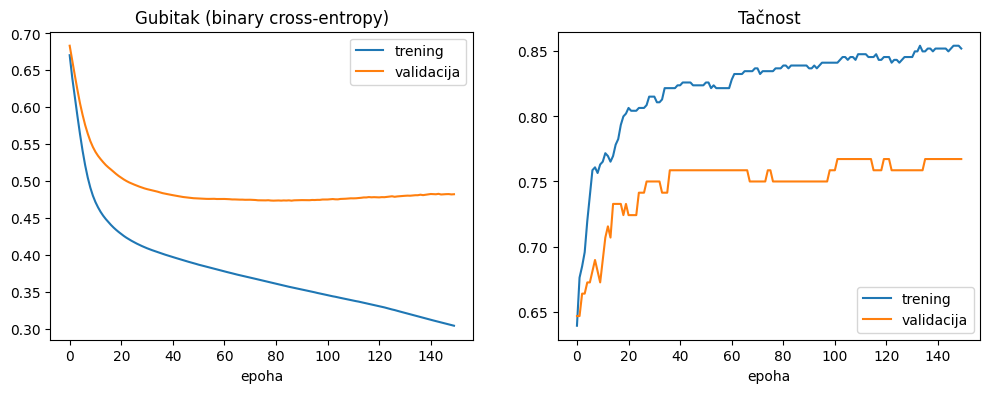

In [20]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# Gubitak (binary cross-entropy) kroz epohe
axs[0].plot(history.history['loss'], label='trening')
axs[0].plot(history.history['val_loss'], label='validacija')
axs[0].set_title('Gubitak (binary cross-entropy)'); axs[0].set_xlabel('epoha'); axs[0].legend()

# Tačnost kroz epohe
axs[1].plot(history.history['accuracy'], label='trening')
axs[1].plot(history.history['val_accuracy'], label='validacija')
axs[1].set_title('Tačnost'); axs[1].set_xlabel('epoha'); axs[1].legend()
plt.show()
# Ako trening gubitak i dalje pada, a validacioni počne da raste, model se preprilagođava (overfitting).

In [21]:
# Čuvamo model i test podatke dijabetesa pod posebnim imenima,
# jer se promenljive model, X_test i y_test kasnije koriste i za druge primere
model_dijabetes, X_test_dijabetes, y_test_dijabetes = model, X_test, y_test


# **Kreiranje i treniranje neuronske mreže pomoću PyTorch biblioteke**


In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Učitavanje Iris dataset-a
iris = load_iris()
X, y = iris.data, iris.target

# Podela dataset-a na trening i test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardizacija
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Definisane arhitekture neuronske mreže
class SimpleNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)  # Input layer
        self.relu = nn.ReLU()                          # Activation function
        self.fc2 = nn.Linear(hidden_size, output_size) # Output layer

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

In [23]:
# Setovanje random semena za reprodukciju
torch.manual_seed(42)


# Definisanje: input size, hidden size, and output size of the neural network
input_size = X.shape[1]
hidden_size = 10
output_size = len(iris.target_names)


# Instanciranje neuronske mreže
model = SimpleNN(input_size, hidden_size, output_size)


# Definisanje funkcije gubitka i optimizacije
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)


# Konvertovanje podataka u tenzore
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.LongTensor(y_train)


# Treniranje modela
num_epochs = 100
for epoch in range(num_epochs):
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)

    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Prikaz gubitka na svakih 10 epoha
    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [10/100], Loss: 0.7783
Epoch [20/100], Loss: 0.5399
Epoch [30/100], Loss: 0.3921
Epoch [40/100], Loss: 0.2934
Epoch [50/100], Loss: 0.2166
Epoch [60/100], Loss: 0.1639
Epoch [70/100], Loss: 0.1284
Epoch [80/100], Loss: 0.1050
Epoch [90/100], Loss: 0.0902
Epoch [100/100], Loss: 0.0800


In [24]:
# Evaluacija modela
with torch.no_grad():
    X_test_tensor = torch.FloatTensor(X_test)
    y_test_tensor = torch.LongTensor(y_test)
    outputs = model(X_test_tensor)
    _, predicted = torch.max(outputs, 1)
    accuracy = (predicted == y_test_tensor).sum().item() / len(y_test_tensor)
    print(f'Accuracy on the test set: {accuracy:.2f}')

Accuracy on the test set: 0.97


## Matrica konfuzije, preciznost, odziv i F1

Tačnost (accuracy) nije uvek dovoljna, naročito kada klase nisu jednako zastupljene. Zato gledamo **matricu konfuzije**: tabelu koja pokazuje koliko je primera model razvrstao tačno, a koliko pogrešno, posebno za svaku klasu.

|  | Predviđeno: 0 | Predviđeno: 1 |
|---|---|---|
| **Stvarno: 0** | TN (stvarno negativni) | FP (lažno pozitivni) |
| **Stvarno: 1** | FN (lažno negativni) | TP (stvarno pozitivni) |

Iz nje računamo:
- **Tačnost** (accuracy) $= \dfrac{TP + TN}{\text{svi}}$: udeo tačnih predikcija,
- **Preciznost** (precision) $= \dfrac{TP}{TP + FP}$: od onih koje je model proglasio pozitivnim, koliko ih zaista jeste,
- **Odziv** (recall, osetljivost, TPR) $= \dfrac{TP}{TP + FN}$: od svih stvarno pozitivnih, koliko ih je model pronašao,
- **F1** $= 2 \cdot \dfrac{\text{preciznost} \cdot \text{odziv}}{\text{preciznost} + \text{odziv}}$: jedan broj koji uravnotežuje preciznost i odziv.

Model daje **verovatnoću**, a klasu dobijamo poređenjem sa **pragom** (obično 0.5). Promenom praga menjaju se i ove metrike, a upravo to prikazuje ROC kriva u sledećem delu.

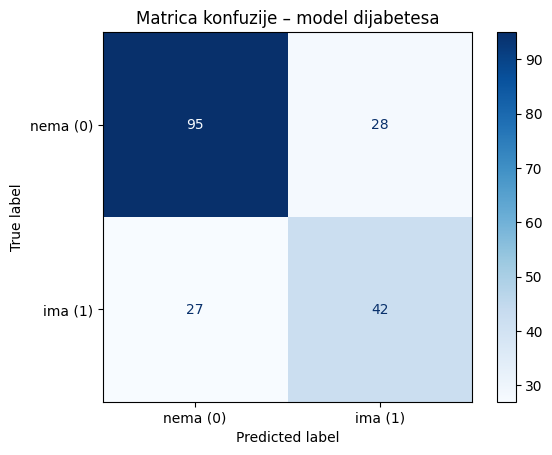

              precision    recall  f1-score   support

    nema (0)      0.779     0.772     0.776       123
     ima (1)      0.600     0.609     0.604        69

    accuracy                          0.714       192
   macro avg      0.689     0.691     0.690       192
weighted avg      0.714     0.714     0.714       192



In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Verovatnoće za test skup (model dijabetesa iz TensorFlow dela) i klase uz prag 0.5
y_prob = model_dijabetes.predict(X_test_dijabetes, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test_dijabetes, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['nema (0)', 'ima (1)']).plot(cmap='Blues')
plt.title('Matrica konfuzije – model dijabetesa'); plt.show()

print(classification_report(y_test_dijabetes, y_pred, target_names=['nema (0)', 'ima (1)'], digits=3))

**Šta je AUC-ROC kriva?**

AUC-ROC kriva je grafikon koji se koristi da se proveri koliko dobro radi model klasifikacije.
Pomaže nam da razumemo koliko dobro model razdvaja pozitivne slučajeve (npr. osobe sa bolešću) od negativnih slučajeva (npr. osobe bez bolesti) na različitim nivoima praga (**threshold**).

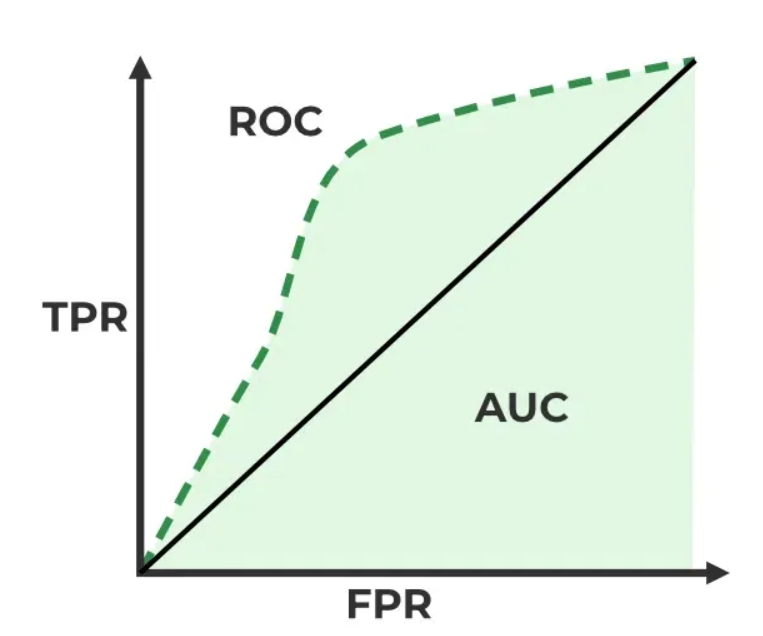

Možemo je razložiti na dva dela:
*   **ROC (Receiver Operating Characteristic) kriva**: prikazuje TPR u odnosu na FPR na različitim pragovima. Predstavlja kompromis između osetljivosti i specifičnosti klasifikatora. ROC je kriva verovatnoće.
*   **AUC (Area under the curve)**: meri površinu ispod ROC krive, odnosno predstavlja stepen ili meru razdvojivosti.Veća vrednost AUC-a ukazuje na bolje performanse modela jer sugeriše veću sposobnost razlikovanja između klasa. Vrednost AUC-a od 1.0 ukazuje na savršene performanse, dok 0.5 sugeriše da se radi o nasumičnom pogađanju.


Pokazuje koliko je model dobar u razlikovanju dve klase tako što prikazuje sledeće vrednosti:

**True Positive Rate (TPR)** – pokazuje koliko često model tačno predviđa pozitivne slučajeve; poznato i kao osetljivost (Sensitivity) ili odziv (Recall).

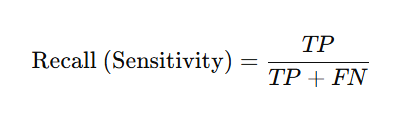



**False Positive Rate (FPR)** – pokazuje koliko često model pogrešno predviđa negativan slučaj kao pozitivan.

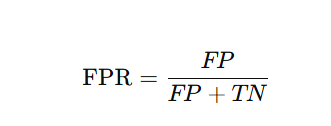

**Specifičnost (Specificity)** – meri udeo stvarno negativnih slučajeva koje je model tačno prepoznao. Računa se kao 1 - FPR.

Što je kriva viša, to je model bolji u donošenju tačnih predikcija.

Performanse modela prema AUC-ROC vrednosti:

* **Visok AUC** (blizu 1): model efikasno razlikuje pozitivne i negativne instance.

* **Nizak AUC** (blizu 0): model sistematski greši, tj. „obrnuto” razvrstava klase (pozitivne proglašava negativnim i obrnuto).

* **AUC oko 0.5**: model ne uči nikakav koristan obrazac — praktično pogađa nasumično.

**AUC-ROC je efikasna metrika kada:**

* Skup podataka je uravnotežen i model treba da se proceni preko svih pragova.
* Lažno pozitivni i lažno negativni rezultati su od sličnog značaja.

Sledeća slika prikazuje kako bi se neki teorijski klasifikatori prikazali na ROC krivoj. Siva isprekidana linija predstavlja klasifikator koji nije bolji od slučajnog pogađanja – ovo će se prikazati kao dijagonalna linija. Ljubičasta linija predstavlja savršen klasifikator – onaj sa stopom stvarno pozitivnih rezultata od 100% i stopom lažno pozitivnih rezultata od 0%. Skoro svi primeri iz stvarnog sveta će se naći negde između ove dve linije – nisu savršeni, ali pružaju veću prediktivnu moć od slučajnog pogađanja. Tipično, ono što tražimo je klasifikator koji održava visoku stopu stvarno pozitivnih rezultata, a istovremeno ima nisku stopu lažno pozitivnih rezultata – ovaj idealan klasifikator bi „zagrlio“ gornji levi ugao slike 1, slično ljubičastoj liniji.

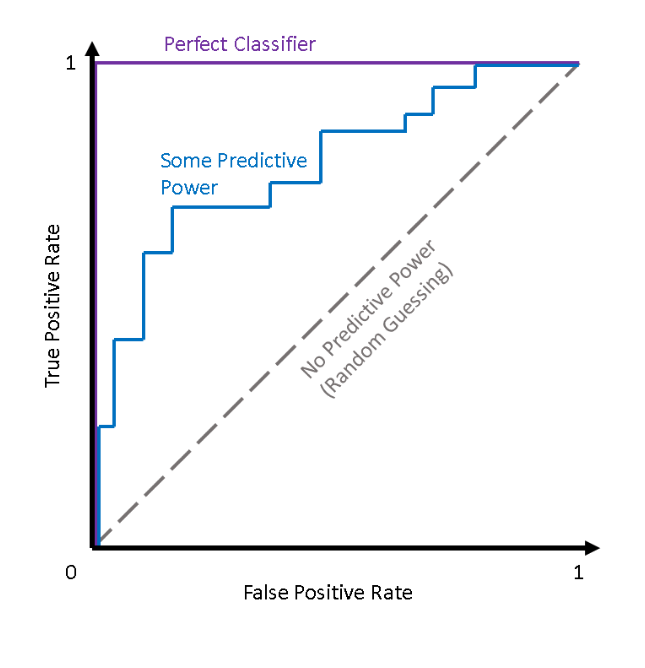

**PRIMER 1**

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

In [27]:
X, y = make_classification(
    n_samples=1000, n_features=20, n_classes=2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [28]:
logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train, y_train)

random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [29]:
y_pred_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_pred_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [30]:
test_df = pd.DataFrame(
    {'True': y_test, 'Logistic': y_pred_logistic, 'RandomForest': y_pred_rf})

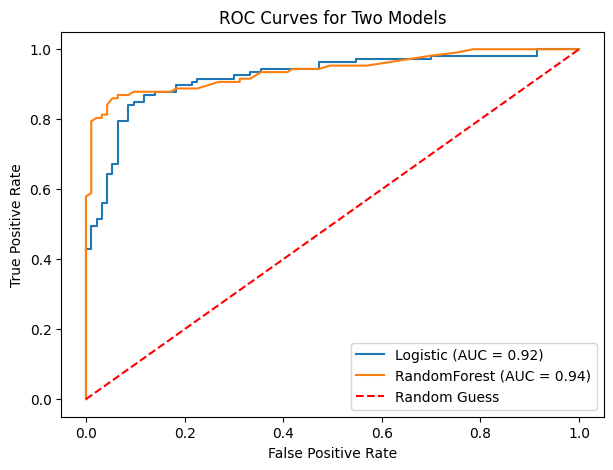

In [31]:
plt.figure(figsize=(7, 5))

for model in ['Logistic', 'RandomForest']:
    fpr, tpr, _ = roc_curve(test_df['True'], test_df[model])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Two Models')
plt.legend()
plt.show()

**ROC kriva za naš model dijabetesa**

Istu analizu možemo uraditi i za neuronsku mrežu koju smo trenirali u TensorFlow-u.

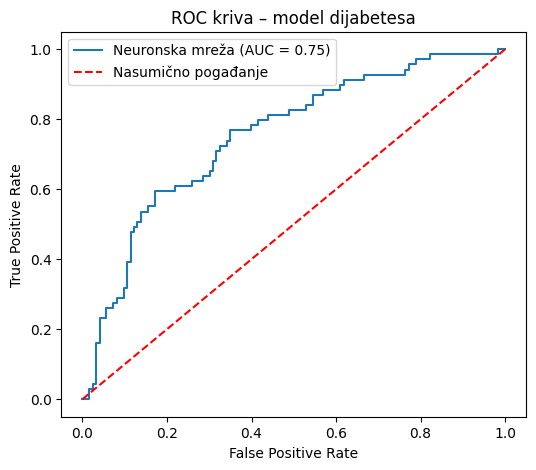

In [32]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_test_dijabetes, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Neuronska mreža (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'r--', label='Nasumično pogađanje')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC kriva – model dijabetesa'); plt.legend(); plt.show()

**Šta je IoU?**

Presek preko unije (IoU) je ključna metrika koja se koristi u računarskom vidu za procenu performansi i tačnosti algoritama za detekciju objekata. Kvantifikuje stepen preklapanja između dva granična okvira: jedan predstavlja **ground truth** (stvarnu lokaciju objekta), a drugi predstavlja **predviđanje** modela za isti objekat. Meri koliko dobro se predviđeni objekat poklapa sa stvarnom anotacijom objekta.

Savršen okvir za predviđanje (100% preklapanje sa okvirom ground truth) imaće IoU od **1.0**.

Kutija za predviđanje bez preklapanja sa okvirom ground truth imaće IoU od **0.0**.

 Viši IoU rezultat podrazumeva tačnije predviđanje.

Ključni pojmovi

* **Object detection** - Praksa pokušaja lokalizacije/detekcije objekta na slici. Na primer, gde je „pas“ na slici?

* **Bounding box** - Na primer gde je pas na slici, okvir bi bio pravougaoni okvir nacrtan oko psa.
* **Bounding box coordinates** - Skup od četiri broja koji prikazuju lokaciju okvira na slici u odnosu na visinu i širinu slike. Može doći u različitim formatima kao što su XYXY ili [x_min, y_min, x_max, y_max], format koji koristite zavisiće od podataka koje imate/okvira koji izaberete.

* **Ground truth bounding box** -  Pravougaona oblast koja obuhvata objekat od interesa na slici. Ona definiše tačnu lokaciju i veličinu objekta na slici i služi kao referentna tačka za procenu predviđanja modela.

* **Prediction bounding box**  - Pravougaona oblast koju generiše model računarskog vida da bi detektovao i lokalizovao objekat na slici. Ona predstavlja procenu algoritma o lokaciji i obimu objekta unutar slike. Stepen preklapanja između predviđene granične kutije i istinite kutije određuje tačnost predviđanja.

* **IoU = Intersection over Union** - Merenje koliko se dobro dve okvira preklapaju. Na primer, upoređivanje prediction box sa ground truth box. Savršena prediction box (100% preklapanje sa ground truth box) imaće IoU rezultat 1.0, dok prediction box bez preklapanja sa kground truth box imaće IoU rezultat 0.0.


**Matematički prikaz je:**


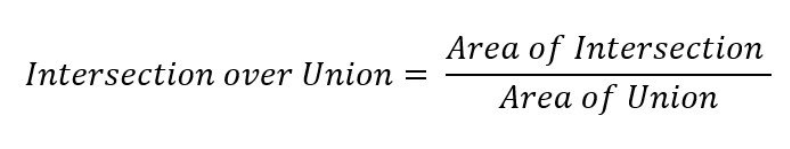

* Area of Intersection = Zajednička površina koju dele dva granična okvira (preklapanje)
* Area of Union = Ukupna površina koju pokrivaju dva granična okvira

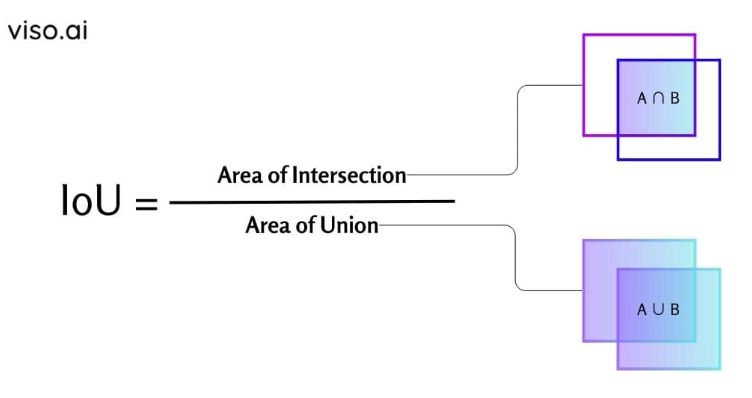

**Overlap** - Preklapanje je termin koji opisuje koliko dva ograničavajuća okvira dele isti prostor. Veće preklapanje ukazuje na bolju lokalizaciju i tačnost predviđenog modela.

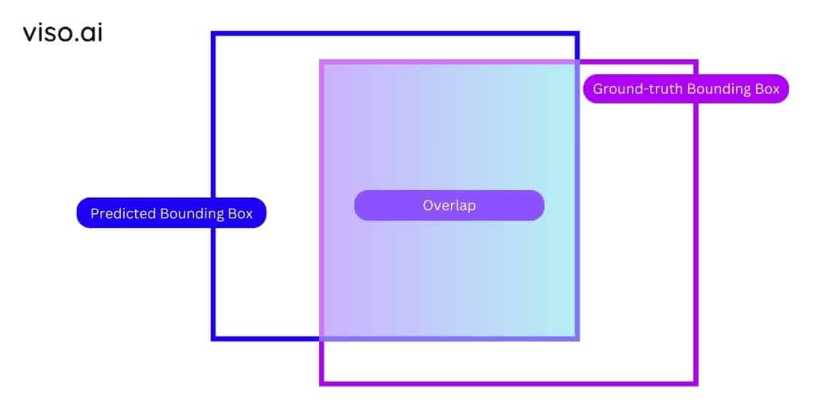

## Kako se računa IoU?

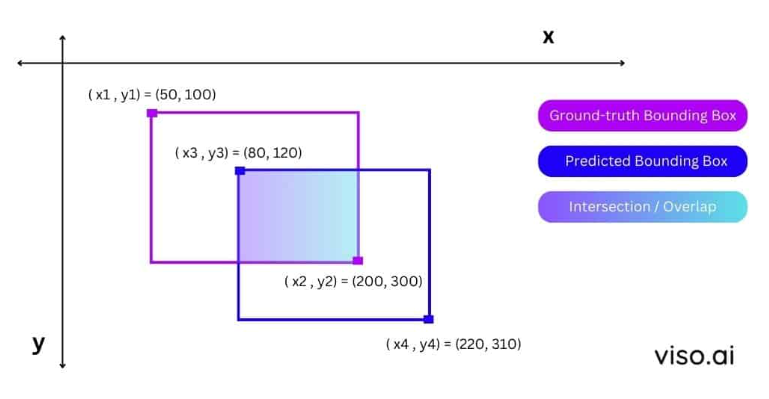


Prilikom poređenja dva okvira:

1. `Ground-truth Bounding Box - box_1` - Koordinate u `XYXY` formatu, npr. `[x_min, y_min, x_max, y_max]`.

2. `Predicted Bounding Box - box_2` - Koordinate u `XYXY` formatu, npr. `[x_min, y_min, x_max, y_max]`


**Površina preseka** se izračunava uzimanjem maksimalne vrednosti minimalnih x i y koordinata (npr. `max(x_min_box_1, x_min_box_2)` i `max(y_min_box_1, y_min_box_2)`).

I minimalne vrednosti maksimalnih x i y koordinata (npr. `min(x_max_box_1, x_max_box_2)` i `min(y_max_box_1, y_max_box_2)`).

```
# Pronalazimo koordinate preseka
intersection_box_x_min = max(x_min_box_1, x_min_box_2)
intersection_box_y_min = max(y_min_box_1, y_min_box_2)
intersection_box_x_max = min(x_max_box_1, x_max_box_2)
intersection_box_y_max = min(y_max_box_1, y_max_box_2)

intersection_box_xyxy = [intersection_box_x_min,
                         intersection_box_y_min,
                         intersection_box_x_max,
                         intersection_box_y_max]

# Određujemo visinu i širinu površine
intersection_height = max(0, intersection_box_y_max - intersection_box_y_min)
intersection_width = max(0, intersection_box_x_max - intersection_box_x_min)

# Određujemo površinu preseka (napomena: može biti 0 ako se okviri ne poklapaju)
intersection_area = intersection_height * intersection_width
```
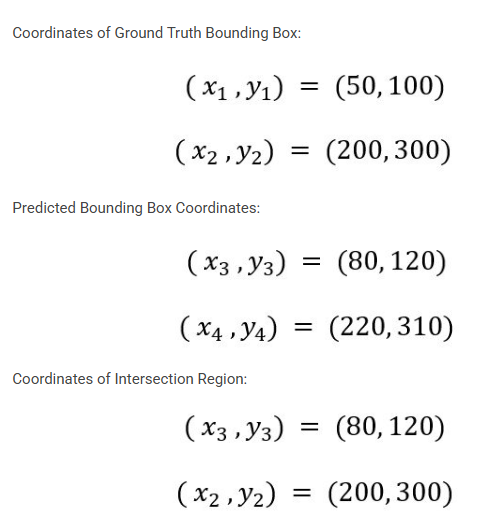

**Računanje površine preseka**


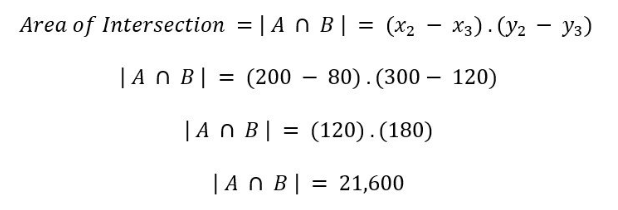


**Računanje površine unije**

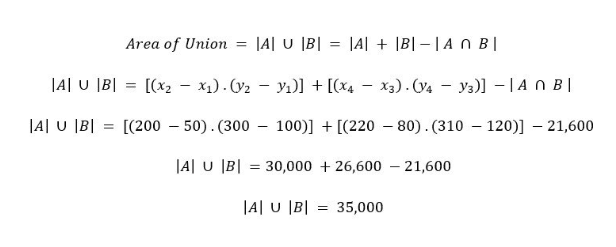


Rezultat ovih operacija su `XYXY` koordinate okvira preseka.

**Površinu preseka** dobijamo množenjem širine i visine okvira preseka (napomena: da bi površina preseka bila veća od nule, širina i visina moraju biti pozitivne, tj. veće od 0; inače se okviri ne preklapaju).

**Površinu unije** dobijamo kada saberemo površine `box_1` i `box_2` i oduzmemo **površinu preseka** (jer bismo je inače računali dva puta).

Konačno, možemo da izračunamo Intersection over Union


iou = intersection_area / union_area

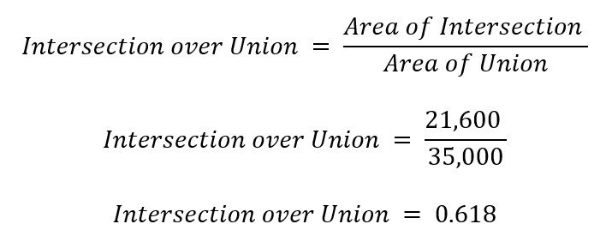

### Računanje IoU matematičkim putem

$$IoU = \frac{\text{Area of Intersection}}{\text{Area of Union}} = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$

Gde su:

* $A$ predstavlja okvir, istog formata kao i $B$.
* $∩$ predstavlja površinu preklapanja (intersection).
* $∪$ predstavlja zajedničku/ukupnu površinu (union).



In [33]:
# Implementacija klase koja će držati koordinate okvira (boxes)
from dataclasses import dataclass, astuple

@dataclass
class Box:
  """Dataclass for holding a set of individual bounding box coordinates in absolute XYXY format."""
  x_min: float
  y_min: float
  x_max: float
  y_max: float

  # Make a check after initializing an instance of Box
  def __post_init__(self):
    self._check_box_coordinate_ordering()

  # Implementiranje provere da li se poštuje pravilo x1 < x2 i y1 < y2 (u suprotnom će box imati negativne koordinate)
  # Imajući klasu podataka koja ovo radi, možemo osigurati validne boxes, sprečavajući greške u nastavku
  def _check_box_coordinate_ordering(self):
    """Checks to make sure x_max > x_min and y_max > y_min"""
    if self.x_min >= self.x_max:
      raise ValueError(f"x_min ({self.x_min}) must be less than x_max ({self.x_max})")
    if self.y_min >= self.y_max:
      raise ValueError(f"y_min ({self.y_min}) must be less than y_max ({self.y_max})")

  # Dodavanje properity-ija klase radi lakšeg pristupa
  @property
  def width(self):
    return self.x_max - self.x_min

  @property
  def height(self):
    return self.y_max - self.y_min

  @property
  def area(self):
    return self.width * self.height

  @property
  def max_coordinate_value(self):
    return max(self.x_min, self.x_max, self.y_min, self.y_max)

  @property
  def min_coordinate_value(self):
    return min(self.x_min, self.x_max, self.y_min, self.y_max)

In [34]:
# Definišemo dva okvira u XYXY formatu: box_1 je ground truth, box_2 je predikcija pomerena za 1 piksel
box_1 = Box(x_min=50, y_min=50, x_max=150, y_max=150)
box_2 = Box(x_min=51, y_min=51, x_max=151, y_max=151)
box_1, box_2

(Box(x_min=50, y_min=50, x_max=150, y_max=150),
 Box(x_min=51, y_min=51, x_max=151, y_max=151))

In [35]:
def calculate_iou(box_1: Box,
                  box_2: Box,
                  return_intersection_box: bool = False) -> float:

  # Korak 1: Računanje koordinata preseka i površine preseka

  # Računanje maksimalne vrednosti za minimalne koordinate
  x_min_intersection = max(box_1.x_min, box_2.x_min)
  y_min_intersection = max(box_1.y_min, box_2.y_min)

  # Računanje minimalne vrednosti za maksimalne koordinate
  x_max_intersection = min(box_1.x_max, box_2.x_max)
  y_max_intersection = min(box_1.y_max, box_2.y_max)

  # Računanje visine i širine za polje preseka
  intersection_width = max(0, x_max_intersection - x_min_intersection)
  intersection_height = max(0, y_max_intersection - y_min_intersection)

  # Računanje površine preseka
  intersection_area = intersection_width * intersection_height

  # Korak 2: Površina unije
  union_area = box_1.area + box_2.area - intersection_area

  # Korak 3: Računanje IoU vrednosti
  iou = round(intersection_area / union_area, 3)

  # Provera da li postoji površina preseka
  if return_intersection_box:
    if intersection_area > 0:
      intersection_box = Box(x_min=x_min_intersection,
                             y_min=y_min_intersection,
                             x_max=x_max_intersection,
                             y_max=y_max_intersection)
      return iou, intersection_box
    else:
      # Ako površina preseka nije preko 0, neće se prikazati okvir za presek
      return iou, None

  return iou

# Testiranje funkcije
iou, intersection_box = calculate_iou(box_1=box_1,
                                      box_2=box_2,
                                      return_intersection_box=True)

print(f"[INFO] IoU between box_1 and box_2: {iou:.3f}")
print(f"[INFO] Intersection box between box_1 and box_2: {intersection_box}")

[INFO] IoU between box_1 and box_2: 0.961
[INFO] Intersection box between box_1 and box_2: Box(x_min=51, y_min=51, x_max=150, y_max=150)


In [36]:
# Pomoćna funkcija za računanje centra okvira
def get_center_coordinates(box: Box) -> tuple[float, float]:
  """Gets center coordinates of a XYXY box and returns them as (center_x, center_y)"""
  center_x = box.x_min + (0.5 * box.width)
  center_y = box.y_min + (0.5 * box.height)

  return (center_x, center_y)

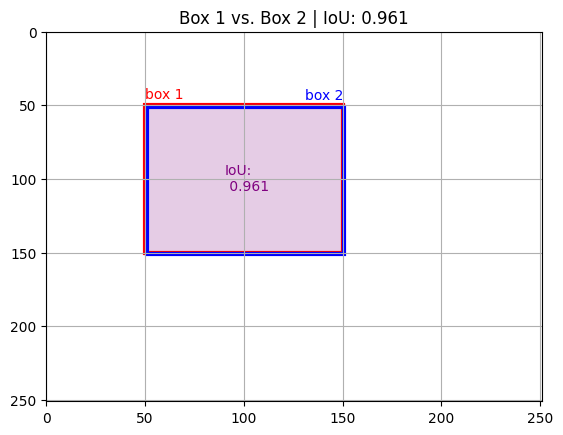

In [37]:
# Plotovanje box_1 and box_2 okvira i označavanje vrednosti IoU
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_two_boxes_with_iou(box_1: Box, box_2: Box):

  # Računanje vrednosti IoU
  iou, intersection_box = calculate_iou(box_1=box_1,
                                        box_2=box_2,
                                        return_intersection_box=True)

  # Kreiranje figura za prikaz i plotovanje
  fig, ax = plt.subplots()

  # Kreiranje okvira za box_1
  rectangle_1 = Rectangle(xy=(box_1.x_min, box_1.y_min),
                          width=box_1.width,
                          height=box_1.height,
                          linewidth=3,
                          edgecolor="r",
                          facecolor="none")
  # Dodavanje teksta za labelu okvira
  ax.text(x=box_1.x_min,
          y=box_1.y_min - 5,
          s="box 1",
          color="r")

  # Kreiranje okvira za box_2
  rectangle_2 = Rectangle(xy=(box_2.x_min, box_2.y_min),
                          width=box_2.width,
                          height=box_2.height,
                          linewidth=3,
                          edgecolor="b",
                          facecolor="none")
  ax.text(x=box_2.x_max - 20,
          y=box_2.y_min - 5,
          s="box 2",
          color="b")

  # Kreiranje okvira za intersection box
  if intersection_box:
    rectangle_intersection = Rectangle(xy=(intersection_box.x_min, intersection_box.y_min),
                                      width=intersection_box.width,
                                      height=intersection_box.height,
                                      linewidth=1,
                                      edgecolor="purple",
                                      facecolor="purple",
                                      alpha=0.2)
    ax.add_patch(rectangle_intersection)

    # Korišćenje centralnih koordinata okvira preseka za vizualizaciju teksta
    intersection_center_x, intersection_center_y = get_center_coordinates(box=intersection_box)

    # Plotovanje IoU teksta u centru unutar okvira
    ax.text(x=intersection_center_x - 10, # adjust coordinates slightly for better centering
            y=intersection_center_y + 7.5,
            s=f"IoU:\n {round(iou, 3)}",
            color="purple")

  # Plotovanje okvira
  ax.add_patch(rectangle_1)
  ax.add_patch(rectangle_2)

  # Podešavanje plota
  max_dim = max(box_1.max_coordinate_value, box_2.max_coordinate_value) + 100
  ax.set_xlim(left=0, right=max_dim)
  ax.set_ylim(bottom=max_dim, top=0)

  # Dodavanje naslova
  plt.title(f"Box 1 vs. Box 2 | IoU: {round(iou, 3)}")

  # Prikaz grid-a
  plt.grid(True)

  # Prikaz plota
  plt.show()

plot_two_boxes_with_iou(box_1=box_1, box_2=box_2)

**PRIMER 2**

In [38]:
# Low IoU box (50 piksela po širini i nadole od box_1)
box_3 = Box(x_min=100,
            y_min=100,
            x_max=200,
            y_max=200)

# No IoU box (nema preklapanja sa box_1)
box_4 = Box(x_min=150,
            y_min=150,
            x_max=250,
            y_max=250)

box_3, box_4

(Box(x_min=100, y_min=100, x_max=200, y_max=200),
 Box(x_min=150, y_min=150, x_max=250, y_max=250))

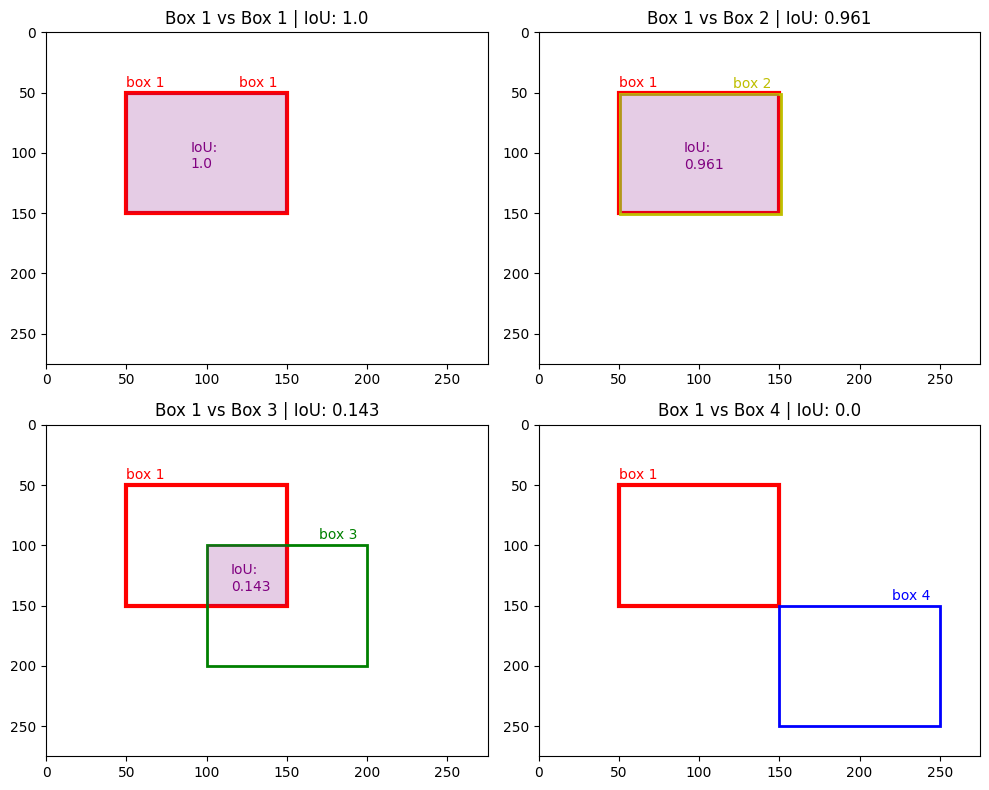

In [39]:
# Plotovanje svih okvira i IoUs u odnosu na box_1 okvir

# Želimo da poredimo sve okvire sa box_1 (uključujući sam box_1)
box_list = [box_1, box_2, box_3, box_4]

# Dodavanja različitih boja za okvire(boxes)
box_colours = ["r", "y", "g", "b"]

# Kreiranje niza podgrafika na osnovu kojih možemo da prikažemo našu komparaciju
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))
axes = ax.flatten()

# Prolazak kroz okvire i plotovanje istih duž osa
for i, box_i in enumerate(box_list):
  ax_current = axes[i]

  # Računjanje IoU and intersection box koordinate
  iou, intersection_box = calculate_iou(box_1=box_1,
                                        box_2=box_i,
                                        return_intersection_box=True)

  # Plotovanje ground truth box-a (box_1)
  box_1_rect = Rectangle(xy=(box_1.x_min,
                             box_1.y_min),
                         width=box_1.width,
                         height=box_1.height,
                         linewidth=3,
                         edgecolor="r",
                         facecolor="none")
  ax_current.add_patch(box_1_rect)
  ax_current.text(x=box_1.x_min,
                  y=box_1.y_min - 5,
                  s="box 1",
                  color="red")

  # Plotovanje ciljni okvir za poređenje (box_i)
  box_i_rect = Rectangle(xy=(box_i.x_min,
                             box_i.y_min),
                         width=box_i.width,
                         height=box_i.height,
                         linewidth=2,
                         edgecolor=box_colours[i],
                         facecolor="none")
  ax_current.add_patch(box_i_rect)
  ax_current.text(x=box_i.x_max - 30,
                  y=box_i.y_min - 5,
                  s=f"box {i+1}",
                  color=box_colours[i])

  # Dodavanje teksta + IoU preklapanja (ako IoU vrednost postoji)
  if iou > 0:
    intersection_rect = Rectangle(xy=(intersection_box.x_min,
                                      intersection_box.y_min),
                                  width=intersection_box.width,
                                  height=intersection_box.height,
                                  linewidth=0,
                                  edgecolor="purple",
                                  facecolor="purple",
                                  alpha=0.2)
    ax_current.add_patch(intersection_rect)

    # Dodavanje IoU teksta
    intersection_center_x, intersection_center_y = get_center_coordinates(box=intersection_box)
    ax_current.text(x=intersection_center_x - 10,
                    y=intersection_center_y + 12.5, # podesiti centar radi boljeg poravnjanja
                    s=f"IoU:\n{iou}",
                    color="purple")

  # Postavljanje limita osa (neophodno, inače je podrazumevano 0-1)
  ax_current.set_xlim(left=0, right=275)
  ax_current.set_ylim(bottom=275, top=0)

  # Dodavanje naziva svakoj osi
  ax_current.set_title(f"Box 1 vs Box {i+1} | IoU: {iou}")

plt.tight_layout()


# Plotujemo
plt.show()

**PRIMER 3**

[INFO] Dimenzije slike (visina, širina, kanali): (300, 451, 3)


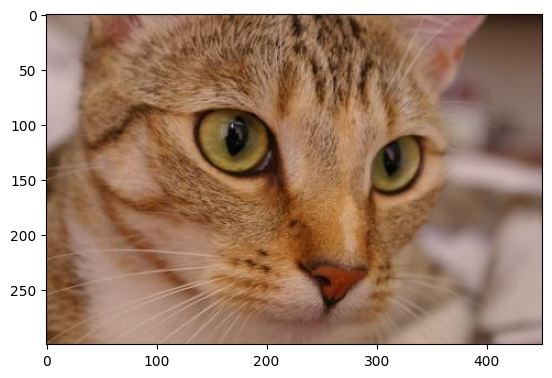

In [40]:
import cv2 as cv
from skimage.io import imread

# Slika mačke koju smo napravili u ćeliji "Priprema slika"
path = '/content/cat.jpg'
img = imread(path)


# Prikazivanje slike
plt.imshow(img);
print(f"[INFO] Dimenzije slike (visina, širina, kanali): {img.shape}")


In [41]:
# Ground truth okvir (anotacija) za glavu mačke je zadat u XYWH formatu: x=60, y=15, širina=360, visina=280.
# Pretvaramo ga u XYXY format, koji koristi naša klasa Box: x_max = x + širina, y_max = y + visina.
box_label_text = 'macka'
box_colour = 'cyan'

real_box_coordinates = Box(x_min=60,
                           y_min=15,
                           x_max=60 + 360,
                           y_max=15 + 280)

print(f"[INFO] Labela okvira: {box_label_text}")
print(f"[INFO] Koordinate okvira: {real_box_coordinates}")

[INFO] Labela okvira: macka
[INFO] Koordinate okvira: Box(x_min=60, y_min=15, x_max=420, y_max=295)


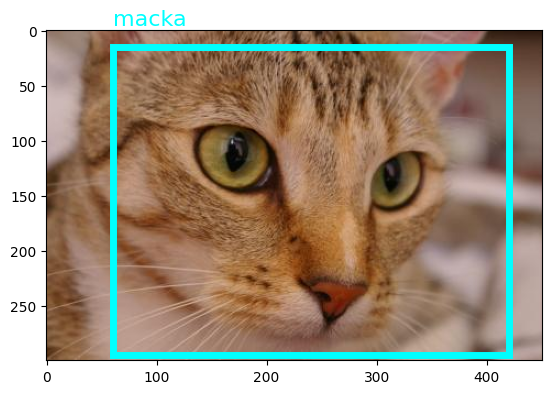

In [42]:
# Plotovanje okvira na slici
annotation_rect = Rectangle(xy=(real_box_coordinates.x_min, real_box_coordinates.y_min),
                            width=real_box_coordinates.width,
                            height=real_box_coordinates.height,
                            linewidth=5,
                            edgecolor=box_colour,
                            facecolor="none")

fig, ax = plt.subplots()
ax.add_patch(annotation_rect)
ax.text(x=real_box_coordinates.x_min,
        y=real_box_coordinates.y_min - 20,
        s=box_label_text,
        color=box_colour,
        fontsize=16)
ax.imshow(img);

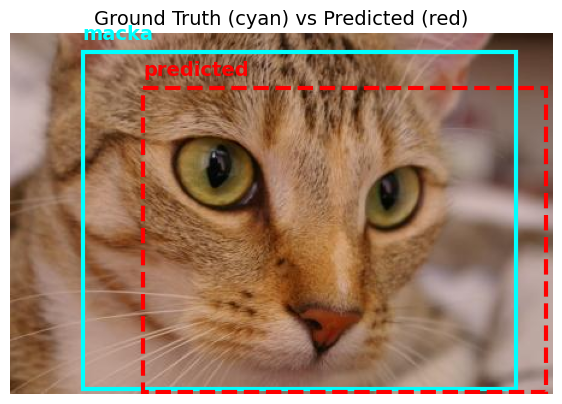

IoU između Ground Truth i Predicted box-a iznosi: 0.717


In [43]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

# ====== Ground Truth box ======
real_box_coordinates = Box(x_min=60, y_min=15, x_max=420, y_max=295)
box_label_text = 'macka'
box_colour = 'cyan'

# ====== Predicted box ======
# Ovo bi bio rezultat "modela"
pred_box = Box(x_min=110, y_min=45, x_max=445, y_max=298)
pred_colour = 'red'

# ====== Nacrtati oba boxa ======
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(img)

# Ground truth box (cyan)
annotation_rect = Rectangle((real_box_coordinates.x_min, real_box_coordinates.y_min),
                            real_box_coordinates.width,
                            real_box_coordinates.height,
                            linewidth=3,
                            edgecolor=box_colour,
                            facecolor="none")
ax.add_patch(annotation_rect)
ax.text(real_box_coordinates.x_min, real_box_coordinates.y_min - 10,
        box_label_text, color=box_colour, fontsize=14, weight='bold')

# Predicted box (red)
pred_rect = Rectangle((pred_box.x_min, pred_box.y_min),
                      pred_box.width,
                      pred_box.height,
                      linewidth=3,
                      edgecolor=pred_colour,
                      linestyle='--',
                      facecolor="none")
ax.add_patch(pred_rect)
ax.text(pred_box.x_min, pred_box.y_min - 10,
        'predicted', color=pred_colour, fontsize=14, weight='bold')

plt.title("Ground Truth (cyan) vs Predicted (red)", fontsize=14)
plt.axis('off')
plt.show()

# ====== Prikazivanje IoU ======
iou_value = calculate_iou(real_box_coordinates, pred_box)
print(f"IoU između Ground Truth i Predicted box-a iznosi: {iou_value:.3f}")


## Mini-zadaci
1. **Zadatak 1 – ROC kriva i AUC**
- Učitaj proizvoljnu sliku iz svog računara (ili koristi neku iz images/ foldera).
- Zadaj stvarne klase (0/1) za nekoliko slika i simulirane verovatnoće modela da slika pripada klasi 1.
- Prikaži ROC krivu.
- Izračunaj vrednost AUC i prikaži je na grafiku.
- ***NAPOMENA***: mogu se koristiti gotove funkcije `roc_curve` i `auc` iz paketa `sklearn.metrics`.

2. **Zadatak 2 – IoU metrika**
- Učitaj proizvoljnu sliku iz svog računara (ili koristi neku iz images/ foldera).
- Prikaži sliku i njene dimenzije (`shape`).
- Zadaj ground truth okvir i prediktovani okvir modela za objekat na slici.
- Nacrtaj oba okvira na slici i izračunaj vrednost IoU.

3. **Zadatak 3 – PyTorch transformacija**
- Učitaj sliku.
- Pretvori je u tenzor pomoću `torchvision.transforms`.
- Promeni dimenzije i prikaži je pre i posle obrade.

4. **Zadatak 4 – Zamućenje slike pomoću PyTorch biblioteke**
- Učitaj sliku i pretvori je u tenzor.
- Pomoću PyTorch-a napravi jednostavan blur filter (kernel 3×3 sa vrednostima 1/9).
- Primeni ga na sliku konvolucijom (`torch.nn.functional.conv2d`).
- Prikaži originalnu i zamućenu sliku jednu pored druge.

---
# Rešenja mini zadataka

### Zadatak 1 – ROC kriva i AUC

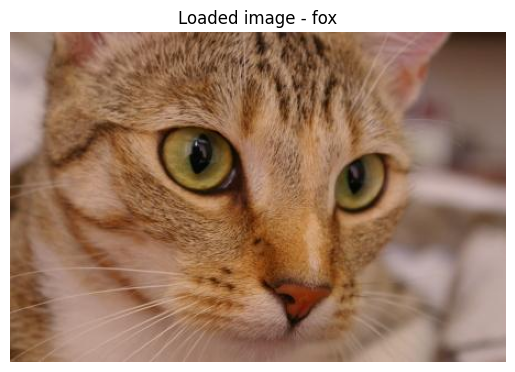

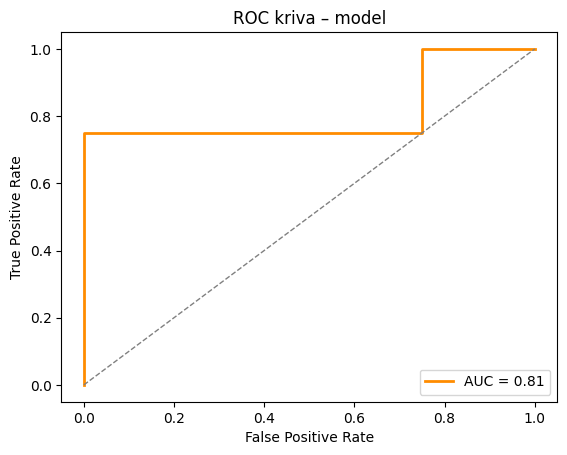

In [44]:
#1.zadatak

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from PIL import Image
from skimage.io import imread

# Putanja do slike (otpremiti sliku u Colab)
path = "/content/animal1.jpg"

# 1. Učitavanje slike
img = imread(path)
plt.imshow(img)
plt.title("Loaded image - fox")
plt.axis('off')
plt.show()

# 2. Simulirani podaci
y_true = [1, 0, 1, 1, 0, 1, 0, 0]      # stvarne klase (1 = lisica, 0 = nije lisica)
y_scores = [0.9, 0.2, 0.8, 0.75, 0.35, 0.25, 0.3, 0.4]  # verovatnoće modela

# 3. Izračunavanje ROC i AUC
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 4. Crtanje ROC krive
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC kriva – model")
plt.legend(loc="lower right")
plt.show()


### Zadatak 2 – IoU metrika

Dimenzije slike (visina, širina, kanali): (300, 451, 3)


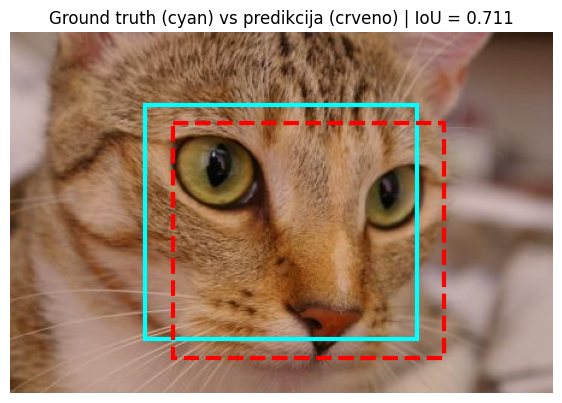

In [45]:
#2. zadatak
from skimage.io import imread
from matplotlib.patches import Rectangle

# 1. Učitavanje slike i dimenzije
path = "/content/animal1.jpg"
img2 = imread(path)
print("Dimenzije slike (visina, širina, kanali):", img2.shape)

# 2. Ground truth i predikcija (primer koordinata; prilagoditi objektu na svojoj slici)
H, W = img2.shape[:2]
gt   = Box(x_min=int(0.25*W), y_min=int(0.20*H), x_max=int(0.75*W), y_max=int(0.85*H))
pred = Box(x_min=int(0.30*W), y_min=int(0.25*H), x_max=int(0.80*W), y_max=int(0.90*H))

# 3. Prikaz oba okvira i IoU
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(img2)
ax.add_patch(Rectangle((gt.x_min, gt.y_min), gt.width, gt.height, linewidth=3, edgecolor='cyan', facecolor='none'))
ax.add_patch(Rectangle((pred.x_min, pred.y_min), pred.width, pred.height, linewidth=3, edgecolor='red', linestyle='--', facecolor='none'))
iou_val = calculate_iou(gt, pred)
ax.set_title(f'Ground truth (cyan) vs predikcija (crveno) | IoU = {iou_val:.3f}')
ax.axis('off'); plt.show()

### Zadatak 3 – PyTorch transformacija

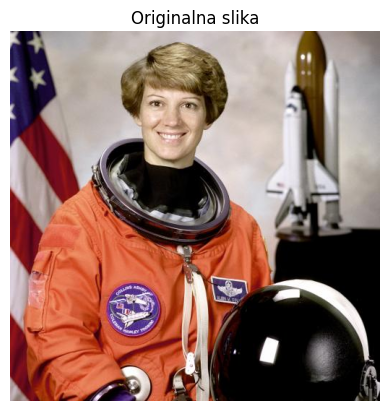

Oblik tenzora: torch.Size([3, 128, 128])


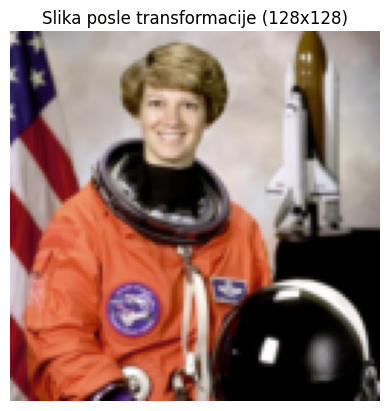

In [46]:

#3. zadatak
import torch
from torchvision import transforms
from skimage.io import imread
import matplotlib.pyplot as plt
from PIL import Image

# 1. Učitavanje slike
path = "/content/animal2.jpg"
image = imread(path)

# Pretvori u PIL
img_pil = Image.fromarray(image)


plt.imshow(image)
plt.title("Originalna slika")
plt.axis('off')
plt.show()

# 2. Transformacija slike (resize + tensor)
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

tensor_image = transform(img_pil)
print("Oblik tenzora:", tensor_image.shape)  # (C, H, W)

# 3. Prikaz slike posle transformacije
plt.imshow(tensor_image.permute(1, 2, 0))  # prebacujemo u (H, W, C)
plt.title("Slika posle transformacije (128x128)")
plt.axis('off')
plt.show()




### Zadatak 4 – Zamućenje slike pomoću PyTorch biblioteke

Ulazni oblik: torch.Size([1, 3, 128, 128])
Izlazni oblik: torch.Size([1, 3, 128, 128])


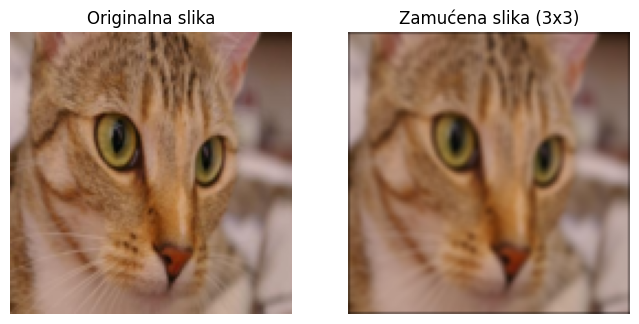

In [47]:
#4.zadatak
import torch
import torch.nn.functional as F
from torchvision import transforms
import matplotlib.pyplot as plt
from PIL import Image
from skimage.io import imread

# 1. Učitavanje slike i pretvaranje u tenzor oblika (1, 3, H, W)
path = "/content/animal1.jpg"
img_pil = Image.fromarray(imread(path)).convert("RGB")
transform = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor()])
img_t = transform(img_pil).unsqueeze(0)          # dodajemo batch dimenziju
print("Ulazni oblik:", img_t.shape)

# 2. Blur kernel: prosek 3x3 (svaki element 1/9)
kernel = torch.ones((3, 3)) / 9.0
kernel = kernel.view(1, 1, 3, 3).repeat(3, 1, 1, 1)   # isti filter za svaki od 3 kanala: oblik (3, 1, 3, 3)

# 3. Konvolucija: groups=3 znači da se svaki kanal filtrira posebno; padding=1 čuva veličinu slike
blurred = F.conv2d(img_t, kernel, padding=1, groups=3)
print("Izlazni oblik:", blurred.shape)

# 4. Prikaz (tenzor (C, H, W) prebacujemo u (H, W, C) za matplotlib)
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(img_t[0].permute(1, 2, 0));   plt.title("Originalna slika"); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(blurred[0].permute(1, 2, 0)); plt.title("Zamućena slika (3x3)"); plt.axis('off')
plt.show()